# Time-Series Foundations

This notebook contrasts white noise, a stationary AR(1) process, and a random walk, using the moments and autocorrelations from the notes on [stationarity](../../notes/time_series/stationarity.md) and [random walks](../../notes/time_series/random_walk.md). The three processes are

$$
\varepsilon_t,\qquad X_t=0.75X_{t-1}+\varepsilon_t,\qquad S_t=S_{t-1}+\varepsilon_t.
$$

## 1. One realization of each process

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

rng = np.random.default_rng(42)
n = 300
white_noise = rng.normal(size=n)
ar1 = np.zeros(n)
for t in range(1, n):
    ar1[t] = 0.75 * ar1[t - 1] + rng.normal()
random_walk = np.cumsum(rng.normal(size=n))

summary = pd.DataFrame({
    'series': ['white noise', 'AR(1)', 'random walk'],
    'mean': [white_noise.mean(), ar1.mean(), random_walk.mean()],
    'variance': [white_noise.var(), ar1.var(), random_walk.var()],
    'lag1_acf': [acf(s, nlags=1, fft=False)[1] for s in (white_noise, ar1, random_walk)],
}).round(3)
summary

,series,mean,variance,lag1_acf
0,white noise,-0.041,0.863,0.091
1,AR(1),-0.020,2.517,0.771
2,random walk,-11.240,33.419,0.972


Theory: the white-noise variance is $1$; the AR(1) variance is $1/(1-0.75^2)=2.286$ with $\rho(1)=0.75$; the random-walk variance is $t$ (growing), and its sample lag-1 ACF is close to $1$ even though the population ACF is undefined.

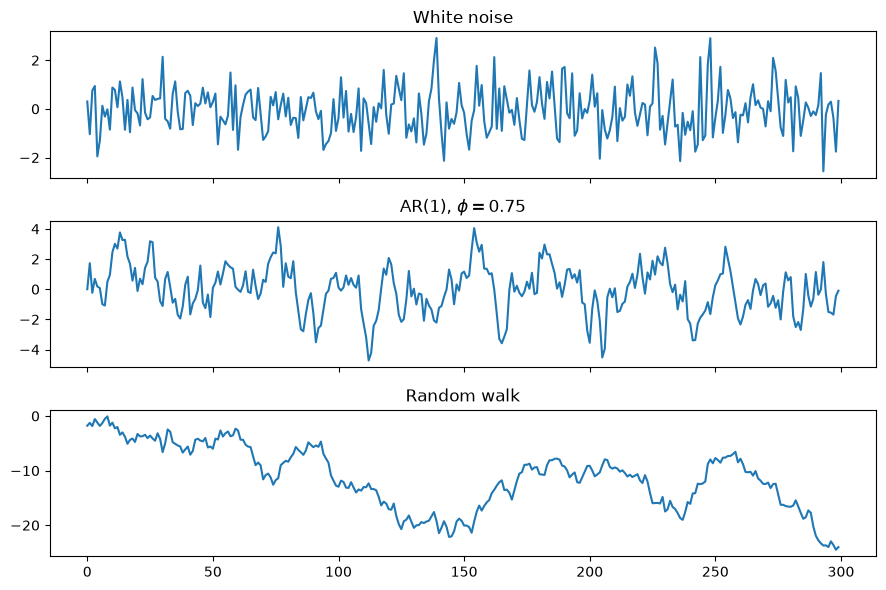

In [2]:
fig, ax = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
for a, s, name in zip(ax, (white_noise, ar1, random_walk), ('White noise', 'AR(1), $\\phi=0.75$', 'Random walk')):
    a.plot(s); a.set_title(name)
plt.tight_layout(); plt.show()

## 2. Variance across many realizations

Stationarity is a property of the *process*, so compare the cross-sectional variance of many independent paths at several times. For the random walk it grows linearly, for the AR(1) it settles at $1/(1-\phi^2)$.

In [3]:
rng = np.random.default_rng(0)
paths = 2000
eps = rng.normal(size=(paths, n))
rw = np.cumsum(eps, axis=1)
ar = np.zeros((paths, n))
for t in range(1, n):
    ar[:, t] = 0.75 * ar[:, t - 1] + eps[:, t]
times = [10, 50, 100, 299]
print(pd.DataFrame({'t': [t + 1 for t in times],
                    'Var white noise': [eps[:, t].var() for t in times],
                    'Var AR(1)': [ar[:, t].var() for t in times],
                    'Var random walk': [rw[:, t].var() for t in times]}).round(2))
print('theory AR(1):', round(1 / (1 - 0.75 ** 2), 3))

     t  Var white noise  Var AR(1)  Var random walk
0   11             1.01       2.49            11.42
1   51             0.95       2.19            52.50
2  101             0.98       2.40            98.42
3  300             0.99       2.26           306.84
theory AR(1): 2.286


The white-noise and AR(1) variances do not depend on $t$ (the AR(1) start-up transient disappears within a handful of steps); the random-walk variance is approximately $t$.

## 3. Sample ACFs and differencing

Differencing a random walk recovers the shocks. The ACF of the level decays very slowly; the ACF of the first difference is near zero.

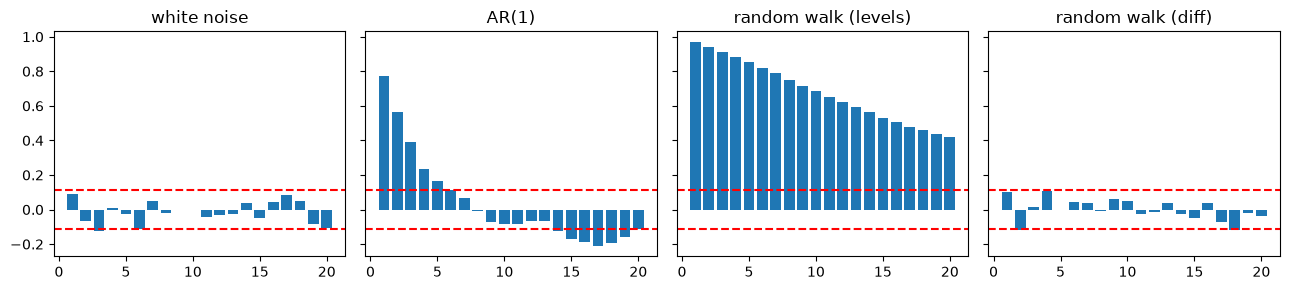

In [4]:
def sample_acf(x, k=20):
    return acf(x, nlags=k, fft=False)[1:]

fig, ax = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for a, s, name in zip(ax, (white_noise, ar1, random_walk, np.diff(random_walk)),
                      ('white noise', 'AR(1)', 'random walk (levels)', 'random walk (diff)')):
    a.bar(range(1, 21), sample_acf(s)); a.set_title(name)
    a.axhline(1.96 / np.sqrt(len(s)), color='r', ls='--'); a.axhline(-1.96 / np.sqrt(len(s)), color='r', ls='--')
plt.tight_layout(); plt.show()

## 4. A unit-root test

The augmented Dickey-Fuller test has a unit-root null, so a small $p$-value is evidence against it.

In [5]:
from statsmodels.tsa.stattools import adfuller
for name, s in [('white noise', white_noise), ('AR(1)', ar1), ('random walk', random_walk), ('diff(random walk)', np.diff(random_walk))]:
    stat, p = adfuller(s, result_object=False)[:2]
    print(f'{name:18s} ADF stat={stat:6.2f}  p={p:.3f}')

white noise        ADF stat=-11.25  p=0.000
AR(1)              ADF stat= -6.30  p=0.000
random walk        ADF stat= -1.13  p=0.704
diff(random walk)  ADF stat=-13.10  p=0.000


The levels of the random walk fail to reject the unit root; after differencing the null is rejected. As in the note, such a test is supporting evidence and depends on deterministic terms and lag choices.